#Step 1: Import Libraries and Set Device

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from google.colab import drive

In [3]:
# Set random seed for reproducibility
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA A100-SXM4-40GB


# Step 2: Load Training, Validation, and Test CSVs

Load the patient-independent training and test image records generated in `02_preprocessing.ipynb`. Verify the number of images, class labels, and patient independence before model training.

In [4]:
# Mount Google Drive
drive.mount("/content/drive")

# Use the same splits as GFNet
split_folder = "/content/drive/MyDrive/COMP3710/project/dataset/splits"

train_df = pd.read_csv(
    os.path.join(split_folder, "train.csv"),
    dtype={"image_id": str, "patient_id": str}
)

val_df = pd.read_csv(
    os.path.join(split_folder, "val.csv"),
    dtype={"image_id": str, "patient_id": str}
)

test_df = pd.read_csv(
    os.path.join(split_folder, "test.csv"),
    dtype={"image_id": str, "patient_id": str}
)

# Display dataset information
for name, records in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} images:", len(records))
    print(f"{name} patients:", records["patient_id"].nunique())
    print(records["label"].value_counts())

# Verify patient independence
train_ids = set(train_df["patient_id"])
val_ids = set(val_df["patient_id"])
test_ids = set(test_df["patient_id"])

assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)

print("\nPASS: All datasets are patient-independent.")

Mounted at /content/drive

Train images: 21620
Train patients: 476
label
NC    11000
AD    10620
Name: count, dtype: int64

Validation images: 4460
Validation patients: 102
label
AD    2240
NC    2220
Name: count, dtype: int64

Test images: 4440
Test patients: 102
label
NC    2440
AD    2000
Name: count, dtype: int64

PASS: All datasets are patient-independent.


# Step 2.1: Extract MRI Images Locally

Extract the MRI images from ZIP files stored in Google Drive into Colab local storage to reduce data loading time during CNN training.

In [5]:
# import os
# import shutil
# import time

# # Set local cache folder
# cache_folder = "/content/mri_cache"

# os.makedirs(cache_folder, exist_ok=True)

# # Combine train and test records
# all_df = pd.concat([train_df, test_df], ignore_index=True)

# start_time = time.time()

# # Copy MRI images to local storage
# for i in range(len(all_df)):

#     source_path = all_df.iloc[i]["path"]

#     # Preserve original train/test and AD/NC folder structure
#     relative_path = os.path.relpath(
#         source_path,
#         "/content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC"
#     )

#     destination_path = os.path.join(cache_folder, relative_path)

#     os.makedirs(
#         os.path.dirname(destination_path),
#         exist_ok=True
#     )

#     if not os.path.exists(destination_path):
#         shutil.copy2(source_path, destination_path)

#     if (i + 1) % 1000 == 0:
#         print(f"Copied {i + 1}/{len(all_df)} images", flush=True)

# elapsed_time = time.time() - start_time

# print("Caching completed.")
# print("Total images:", len(all_df))
# print("Time:", elapsed_time, "seconds")

import os
import zipfile
import time

# Set dataset paths
source_folder = "/content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC"
cache_folder = "/content/mri_cache"

start_time = time.time()

# Extract training and test ZIP files
for split in ["train", "test"]:

    for label in ["AD", "NC"]:

        zip_path = os.path.join(
            source_folder, split, label + ".zip"
        )

        output_folder = os.path.join(
            cache_folder, split, label
        )

        os.makedirs(output_folder, exist_ok=True)

        print("Extracting:", zip_path, flush=True)

        with zipfile.ZipFile(zip_path, "r") as zip_file:
            zip_file.extractall(output_folder)

        print("Finished:", split, label, flush=True)

elapsed_time = time.time() - start_time

print("\nExtraction completed.")
print("Time:", elapsed_time, "seconds")

Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/train/AD.zip
Finished: train AD
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/train/NC.zip
Finished: train NC
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/test/AD.zip
Finished: test AD
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/test/NC.zip
Finished: test NC

Extraction completed.
Time: 22.590354204177856 seconds


In [6]:
# Check extracted folder structure
for split in ["train", "test"]:
    for label in ["AD", "NC"]:

        folder = os.path.join(cache_folder, split, label)

        print("\nFolder:", folder)
        print("First 5 items:", os.listdir(folder)[:5])


Folder: /content/mri_cache/train/AD
First 5 items: ['360982_82.jpeg', '297483_85.jpeg', '369145_95.jpeg', '317202_104.jpeg', '323260_102.jpeg']

Folder: /content/mri_cache/train/NC
First 5 items: ['1304066_93.jpeg', '982345_104.jpeg', '1092491_104.jpeg', '1070417_97.jpeg', '995457_103.jpeg']

Folder: /content/mri_cache/test/AD
First 5 items: ['388630_83.jpeg', '1344946_92.jpeg', '395983_78.jpeg', '1189177_91.jpeg', '395983_86.jpeg']

Folder: /content/mri_cache/test/NC
First 5 items: ['1327191_108.jpeg', '1259842_96.jpeg', '1229457_81.jpeg', '1273042_100.jpeg', '1319400_99.jpeg']


# Step 2.2: Update Image Paths

Update the training and test image paths to use the local MRI cache. Verify that all cached images exist before creating the PyTorch datasets.

In [7]:
# # Set original dataset folder
# original_folder = "/content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC"

# # Update training image paths
# for i in range(len(train_df)):

#     original_path = train_df.iloc[i]["path"]

#     relative_path = os.path.relpath(
#         original_path,
#         original_folder
#     )

#     local_path = os.path.join(cache_folder, relative_path)

#     train_df.at[train_df.index[i], "path"] = local_path

# # Update test image paths
# for i in range(len(test_df)):

#     original_path = test_df.iloc[i]["path"]

#     relative_path = os.path.relpath(
#         original_path,
#         original_folder
#     )

#     local_path = os.path.join(cache_folder, relative_path)

#     test_df.at[test_df.index[i], "path"] = local_path

# # Verify local image paths
# missing_train = 0
# missing_test = 0

# for path in train_df["path"]:
#     if not os.path.isfile(path):
#         missing_train += 1

# for path in test_df["path"]:
#     if not os.path.isfile(path):
#         missing_test += 1

# print("Missing train images:", missing_train)
# print("Missing test images:", missing_test)

# print("\nExample local path:")
# print(train_df.iloc[0]["path"])

# assert missing_train == 0
# assert missing_test == 0

# print("\nPASS: All image paths point to local cached files.")

# Original image root and local cache root
source_folder = (
    "/content/drive/MyDrive/COMP3710/project/"
    "dataset/raw/ADNI/AD_NC"
)
cache_folder = "/content/mri_cache"

# Preserve each image's original folder location
def get_local_path(original_path):
    relative_path = os.path.relpath(original_path, source_folder)
    return os.path.join(cache_folder, relative_path)

for name, records in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    records["local_path"] = records["path"].apply(get_local_path)

    missing = records.loc[
        ~records["local_path"].map(os.path.isfile),
        "local_path"
    ]

    print(f"\n{name} images:", len(records))
    print("Missing cached images:", len(missing))

    if len(missing):
        print(missing.head().to_string(index=False))

    assert len(missing) == 0, f"{name}: cached images are missing."

print("\nPASS: All cached image files exist.")


Train images: 21620
Missing cached images: 0

Validation images: 4460
Missing cached images: 0

Test images: 4440
Missing cached images: 0

PASS: All cached image files exist.


In [8]:
# Find missing training images
for path in train_df["path"]:

    if not os.path.isfile(path):
        print("Missing image:", path)

In [9]:
# Check original and duplicate images
folder = "/content/mri_cache/train/NC"

original = os.path.join(folder, "976382_96.jpeg")
duplicate = os.path.join(folder, "976382_96 (1).jpeg")

print("Original exists:", os.path.isfile(original))
print("Duplicate exists:", os.path.isfile(duplicate))

Original exists: True
Duplicate exists: False


# Step 3: Define Image Transforms

Resize grayscale MRI images to 128 × 128 pixels, convert them into PyTorch tensors, and normalize pixel intensities for CNN training. The same preprocessing will be applied to the GFNet model for a fair comparison.

In [10]:
# # Set image size
# image_size = 128

# # Define image preprocessing
# image_transform = transforms.Compose([
#     transforms.Resize((image_size, image_size)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.5], std=[0.5])
# ])

# print("Image transform:")
# print(image_transform)

image_size = 256

# Validation and test preprocessing
image_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Training-only augmentation
train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),

    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.98, 1.02),
        interpolation=transforms.InterpolationMode.BILINEAR,
        fill=0
    ),

    transforms.ToTensor(),

    transforms.RandomErasing(
        p=0.4,
        scale=(0.01, 0.10),
        ratio=(0.5, 2.0),
        value=0
    ),

    transforms.RandomApply([
        transforms.ElasticTransform(
            alpha=10.0,
            sigma=3.0,
            interpolation=transforms.InterpolationMode.BILINEAR,
            fill=0
        )
    ], p=0.3),

    transforms.Normalize(mean=[0.5], std=[0.5])
])

print("Training transforms:")
print(train_transform)
print("\nValidation/test transforms:")
print(image_transform)

Training transforms:
Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.05, 0.05), scale=(0.98, 1.02), interpolation=bilinear)
    ToTensor()
    RandomErasing(p=0.4, scale=(0.01, 0.1), ratio=(0.5, 2.0), value=0, inplace=False)
    RandomApply(
    p=0.3
    ElasticTransform(alpha=[10.0, 10.0], sigma=[3.0, 3.0], interpolation=InterpolationMode.BILINEAR, fill=[0.0])
)
    Normalize(mean=[0.5], std=[0.5])
)

Validation/test transforms:
Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5], std=[0.5])
)


# Step 4: Create PyTorch Dataset

Define a custom PyTorch Dataset to load MRI images from the CSV records, apply image preprocessing, and convert AD/NC labels into numerical values for binary classification.

In [11]:
class MRIDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        # Convert class labels to numbers
        self.label_map = {
            "NC": 0,
            "AD": 1
        }

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        # Get one image record
        record = self.dataframe.iloc[idx]

        # Load image as grayscale
        with Image.open(record["local_path"]) as source:
          image = source.convert("L")

        # Apply preprocessing
        if self.transform is not None:
            image = self.transform(image)

        # Convert label to integer
        label = self.label_map[record["label"]]

        return image, label

In [12]:
# # Create datasets
# train_dataset = MRIDataset(
#     dataframe=train_df,
#     transform=image_transform
# )

# test_dataset = MRIDataset(
#     dataframe=test_df,
#     transform=image_transform
# )

# print("Train dataset size:", len(train_dataset))
# print("Test dataset size:", len(test_dataset))

train_dataset = MRIDataset(
    dataframe=train_df,
    transform=train_transform
)

val_dataset = MRIDataset(
    dataframe=val_df,
    transform=image_transform
)

test_dataset = MRIDataset(
    dataframe=test_df,
    transform=image_transform
)

print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Test dataset size:", len(test_dataset))

Train dataset size: 21620
Validation dataset size: 4460
Test dataset size: 4440


In [13]:
# Load one sample
sample_image, sample_label = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Image dtype:", sample_image.dtype)
print("Label:", sample_label)
print("Pixel range:", sample_image.min().item(), sample_image.max().item())

Image shape: torch.Size([1, 256, 256])
Image dtype: torch.float32
Label: 1
Pixel range: -1.0 0.766572117805481


# Step 5: Create DataLoaders

Create training and test DataLoaders to load MRI images in batches. Shuffle the training data for model learning while keeping the test data in a fixed order for evaluation.

In [14]:
# # Set batch size
# batch_size = 32

# # Create training DataLoader
# train_loader = DataLoader(
#     train_dataset,
#     batch_size=batch_size,
#     shuffle=True,
#     num_workers=2
# )

# # Create test DataLoader
# test_loader = DataLoader(
#     test_dataset,
#     batch_size=batch_size,
#     shuffle=False,
#     num_workers=2
# )

# print("Train batches:", len(train_loader))
# print("Test batches:", len(test_loader))
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 676
Validation batches: 140
Test batches: 139


In [15]:
# Load one batch
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("First 10 labels:", labels[:10])

Batch image shape: torch.Size([32, 1, 256, 256])
Batch label shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
First 10 labels: tensor([0, 1, 1, 1, 1, 0, 1, 0, 1, 1])


# Step 6: Build CNN Model

Define a CNN baseline with three convolutional blocks for extracting spatial features from grayscale MRI images. Global average pooling and a fully connected layer are used to predict the two classes: Normal Control (NC) and Alzheimer's Disease (AD).

In [16]:
class CNNBaseline(nn.Module):

    def __init__(self):
        super().__init__()

        # Convolutional feature extraction
        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Global average pooling
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classification layer
        self.classifier = nn.Linear(128, 2)

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x

In [17]:
# Create CNN model
model = CNNBaseline().to(device)

print(model)

# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters())

print("\nTotal parameters:", total_params)

CNNBaseline(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)

Total parameters: 92930


In [18]:
# Test forward pass
images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 256, 256])
Output shape: torch.Size([32, 2])


# Step 7: Train CNN Model

Train the CNN baseline using cross-entropy loss and the Adam optimizer. Record training loss and accuracy for each epoch to monitor model learning. The test set is reserved for final evaluation.

In [20]:
# # Set training parameters
# epochs = 30
# learning_rate = 0.001

# # Define loss function
# criterion = nn.CrossEntropyLoss()

# # Define optimizer
# optimizer = optim.Adam(
#     model.parameters(),
#     lr=learning_rate
# )

# # Store training history
# train_loss_history = []
# train_acc_history = []

# print("Epochs:", epochs)
# print("Learning rate:", learning_rate)
# print("Loss function:", criterion)
# print("Optimizer: Adam")

# Reset seeds and initialize a fresh CNN
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

model = CNNBaseline().to(device)

epochs = 30
learning_rate = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

train_loss_history = []
train_acc_history = []
val_loss_history = []
val_acc_history = []

best_val_loss = float("inf")
best_epoch = 0

checkpoint_path = (
    "/content/drive/MyDrive/COMP3710/project/"
    "models/cnn_baseline_best.pth"
)
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

print("Epochs:", epochs)
print("Learning rate:", learning_rate)
print("Optimizer: Adam")
print("Checkpoint:", checkpoint_path)

Epochs: 30
Learning rate: 0.001
Optimizer: Adam
Checkpoint: /content/drive/MyDrive/COMP3710/project/models/cnn_baseline_best.pth


In [21]:
print("Train loader:", len(train_loader))
print("Model device:", next(model.parameters()).device)

Train loader: 676
Model device: cuda:0


In [22]:
# # Train CNN model
# for epoch in range(epochs):

#     # Set model to training mode
#     model.train()

#     total_loss = 0.0
#     correct = 0
#     total = 0

#     for images, labels in train_loader:

#         # Move images and labels to GPU
#         images = images.to(device)
#         labels = labels.to(device)

#         # Clear previous gradients
#         optimizer.zero_grad()

#         # Forward pass
#         outputs = model(images)

#         # Compute loss
#         loss = criterion(outputs, labels)

#         # Backward pass
#         loss.backward()

#         # Update model parameters
#         optimizer.step()

#         # Accumulate loss weighted by batch size
#         total_loss += loss.item() * images.size(0)

#         # Get predicted classes
#         predictions = torch.argmax(outputs, dim=1)

#         # Count correct predictions
#         correct += (predictions == labels).sum().item()
#         total += labels.size(0)

#     # Calculate average loss and accuracy
#     epoch_loss = total_loss / total
#     epoch_acc = correct / total

#     # Save training history
#     train_loss_history.append(epoch_loss)
#     train_acc_history.append(epoch_acc)

#     print(
#         f"Epoch [{epoch + 1}/{epochs}] "
#         f"Loss: {epoch_loss:.4f} "
#         f"Accuracy: {epoch_acc * 100:.2f}%"
#     )

for epoch in range(epochs):

    # 1. Training
    model.train()
    train_total_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_total_loss += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_total_loss / train_total
    train_acc = train_correct / train_total

    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)

    # 2. Validation
    model.eval()
    val_total_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_total_loss += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_total_loss / val_total
    val_acc = val_correct / val_total

    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)

    # 3. Save the best validation model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(model.state_dict(), checkpoint_path)
        print(f"Best model saved at Epoch {best_epoch}")

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2%}",
        flush=True
    )

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", checkpoint_path)

Best model saved at Epoch 1
Epoch [1/30] Train Loss: 0.6742 Train Acc: 56.94% | Val Loss: 0.5906 Val Acc: 71.12%
Best model saved at Epoch 2
Epoch [2/30] Train Loss: 0.6187 Train Acc: 65.86% | Val Loss: 0.5481 Val Acc: 73.03%
Best model saved at Epoch 3
Epoch [3/30] Train Loss: 0.6057 Train Acc: 67.11% | Val Loss: 0.5223 Val Acc: 74.42%
Epoch [4/30] Train Loss: 0.5951 Train Acc: 68.26% | Val Loss: 0.6487 Val Acc: 63.45%
Epoch [5/30] Train Loss: 0.5843 Train Acc: 69.36% | Val Loss: 0.6022 Val Acc: 65.92%
Best model saved at Epoch 6
Epoch [6/30] Train Loss: 0.5694 Train Acc: 70.37% | Val Loss: 0.5117 Val Acc: 75.29%
Best model saved at Epoch 7
Epoch [7/30] Train Loss: 0.5620 Train Acc: 71.17% | Val Loss: 0.4884 Val Acc: 76.46%
Epoch [8/30] Train Loss: 0.5556 Train Acc: 71.94% | Val Loss: 0.5487 Val Acc: 72.69%
Best model saved at Epoch 9
Epoch [9/30] Train Loss: 0.5448 Train Acc: 72.36% | Val Loss: 0.4664 Val Acc: 78.41%
Epoch [10/30] Train Loss: 0.5376 Train Acc: 72.96% | Val Loss: 0.48

In [ ]:
# import time

# # Measure DataLoader speed
# start_time = time.time()

# for batch_idx, (images, labels) in enumerate(train_loader):

#     if batch_idx == 9:
#         break

# elapsed_time = time.time() - start_time

# print("Time for 10 batches:", elapsed_time, "seconds")
# print("Average time per batch:", elapsed_time / 10, "seconds")

Time for 10 batches: 0.2756919860839844 seconds
Average time per batch: 0.02756919860839844 seconds


In [ ]:
# import time

# # Create one batch directly on GPU
# images = torch.randn(32, 1, 128, 128, device=device)
# labels = torch.randint(0, 2, (32,), device=device)

# model.train()

# # Warm up GPU
# for i in range(3):
#     optimizer.zero_grad()
#     outputs = model(images)
#     loss = criterion(outputs, labels)
#     loss.backward()
#     optimizer.step()

# torch.cuda.synchronize()

# # Forward pass
# start = time.time()

# outputs = model(images)
# loss = criterion(outputs, labels)

# torch.cuda.synchronize()
# print("Forward time:", time.time() - start)

# # Backward pass
# optimizer.zero_grad()
# start = time.time()

# loss.backward()

# torch.cuda.synchronize()
# print("Backward time:", time.time() - start)

# # Optimizer step
# start = time.time()

# optimizer.step()

# torch.cuda.synchronize()
# print("Optimizer time:", time.time() - start)

Forward time: 0.0011129379272460938
Backward time: 0.0036847591400146484
Optimizer time: 0.0006296634674072266


In [ ]:
# import time

# # Set model to training mode
# model.train()

# # 1. Load one batch from DataLoader
# start = time.time()

# images, labels = next(iter(train_loader))

# print("Data loading time:", time.time() - start, "seconds", flush=True)

# # 2. Transfer batch to GPU
# start = time.time()

# images = images.to(device)
# labels = labels.to(device)

# torch.cuda.synchronize()

# print("GPU transfer time:", time.time() - start, "seconds", flush=True)

# # 3. Forward pass
# start = time.time()

# outputs = model(images)
# loss = criterion(outputs, labels)

# torch.cuda.synchronize()

# print("Forward time:", time.time() - start, "seconds", flush=True)

# # 4. Backward pass
# optimizer.zero_grad()

# start = time.time()

# loss.backward()

# torch.cuda.synchronize()

# print("Backward time:", time.time() - start, "seconds", flush=True)

# # 5. Optimizer step
# start = time.time()

# optimizer.step()

# torch.cuda.synchronize()

# print("Optimizer time:", time.time() - start, "seconds", flush=True)

Data loading time: 0.13584184646606445 seconds
GPU transfer time: 0.0018546581268310547 seconds
Forward time: 0.0018069744110107422 seconds
Backward time: 0.004027366638183594 seconds
Optimizer time: 0.0011789798736572266 seconds


In [ ]:
# import time

# # Set model to training mode
# model.train()

# # Measure training speed
# start_time = time.time()

# for batch_idx, (images, labels) in enumerate(train_loader):

#     # Move data to GPU
#     images = images.to(device)
#     labels = labels.to(device)

#     # Clear gradients
#     optimizer.zero_grad()

#     # Forward pass
#     outputs = model(images)

#     # Calculate loss
#     loss = criterion(outputs, labels)

#     # Backward pass
#     loss.backward()

#     # Update parameters
#     optimizer.step()

#     # Stop after 10 batches
#     if batch_idx == 9:
#         break

# # Wait for GPU operations to finish
# if torch.cuda.is_available():
#     torch.cuda.synchronize()

# elapsed_time = time.time() - start_time

# print("Time for 10 training batches:", elapsed_time, "seconds")
# print("Average time per training batch:", elapsed_time / 10, "seconds")

Time for 10 training batches: 0.2785518169403076 seconds
Average time per training batch: 0.027855181694030763 seconds


#Step 8: Visualize CNN Training Results

Plot the training loss and accuracy across epochs to examine the learning progress of the CNN baseline.

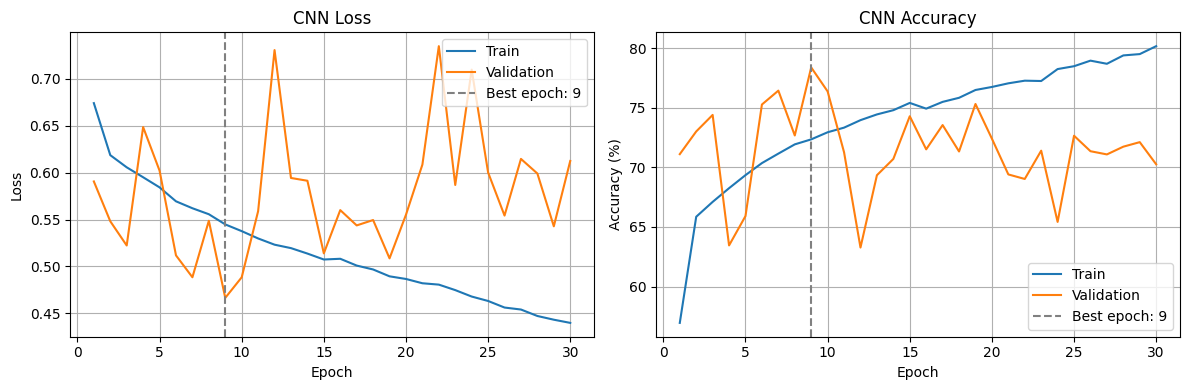

In [23]:
# import matplotlib.pyplot as plt

# # Create epoch numbers
# epoch_numbers = []

# for i in range(len(train_loss_history)):
#     epoch_numbers.append(i + 1)


# # Convert accuracy to percentage
# train_acc_percent = []

# for acc in train_acc_history:
#     train_acc_percent.append(acc * 100)


# # Create two plots
# plt.figure(figsize=(12, 4))


# # Plot training loss
# plt.subplot(1, 2, 1)

# plt.plot(epoch_numbers, train_loss_history, marker="o")

# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.title("CNN Training Loss")
# plt.grid(True)


# # Plot training accuracy
# plt.subplot(1, 2, 2)

# plt.plot(epoch_numbers, train_acc_percent, marker="o")

# plt.xlabel("Epoch")
# plt.ylabel("Accuracy (%)")
# plt.title("CNN Training Accuracy")
# plt.grid(True)


# # Adjust layout

epoch_numbers = range(1, len(train_loss_history) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epoch_numbers, train_loss_history, label="Train")
axes[0].plot(epoch_numbers, val_loss_history, label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("CNN Loss")

axes[1].plot(
    epoch_numbers, np.array(train_acc_history) * 100,
    label="Train"
)
axes[1].plot(
    epoch_numbers, np.array(val_acc_history) * 100,
    label="Validation"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("CNN Accuracy")

for ax in axes:
    ax.axvline(
        best_epoch, color="gray", linestyle="--",
        label=f"Best epoch: {best_epoch}"
    )
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# Step 9: Save CNN Model

Save the trained CNN baseline and its training history to Google Drive for reproducibility and future evaluation.

In [24]:
# import os
# import torch

# # Set output folder
# output_folder = "/content/drive/MyDrive/COMP3710/project/models"

# os.makedirs(output_folder, exist_ok=True)

# # Set model path
# model_path = os.path.join(output_folder, "cnn_baseline.pth")

# # Save model and training history
# torch.save({
#     "model_state_dict": model.state_dict(),
#     "optimizer_state_dict": optimizer.state_dict(),
#     "epochs": epochs,
#     "learning_rate": learning_rate,
#     "train_loss_history": train_loss_history,
#     "train_acc_history": train_acc_history
# }, model_path)

# print("CNN model saved to:", model_path)
# print("File size:", os.path.getsize(model_path), "bytes")

# Load the best CNN checkpoint
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

total_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

print("Loaded checkpoint:", checkpoint_path)
print("Validation images:", total)
print(f"Validation Loss: {total_loss / total:.4f}")
print(f"Validation Accuracy: {correct / total:.2%}")

Loaded checkpoint: /content/drive/MyDrive/COMP3710/project/models/cnn_baseline_best.pth
Validation images: 4460
Validation Loss: 0.4664
Validation Accuracy: 78.41%


#Step10


In [25]:
# Evaluate the best CNN on the test set
model.eval()

test_total_loss = 0.0
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_total_loss += loss.item() * labels.size(0)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )
        all_probabilities.extend(
            torch.softmax(outputs, dim=1)[:, 1].cpu().tolist()
        )

test_loss = test_total_loss / len(all_labels)
test_acc = accuracy_score(all_labels, all_predictions)

print("CNN Test Results")
print("-------------------------")
print("Test images:", len(all_labels))
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2%}")

CNN Test Results
-------------------------
Test images: 4440
Test Loss: 0.5577
Test Accuracy: 71.82%


              precision    recall  f1-score   support

          NC     0.7211    0.7947    0.7561      2440
          AD     0.7139    0.6250    0.6665      2000

    accuracy                         0.7182      4440
   macro avg     0.7175    0.7098    0.7113      4440
weighted avg     0.7178    0.7182    0.7157      4440

Balanced Accuracy: 0.7098
AUROC: 0.7869


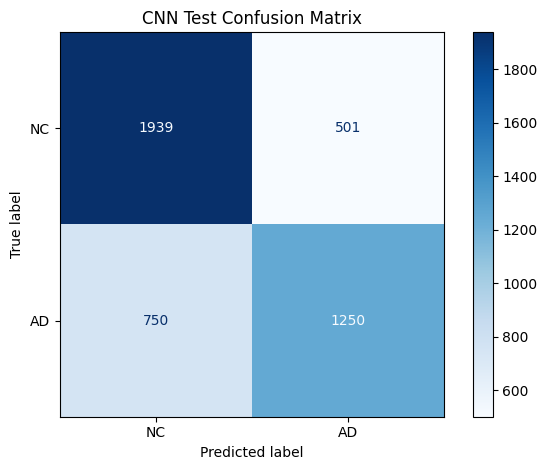

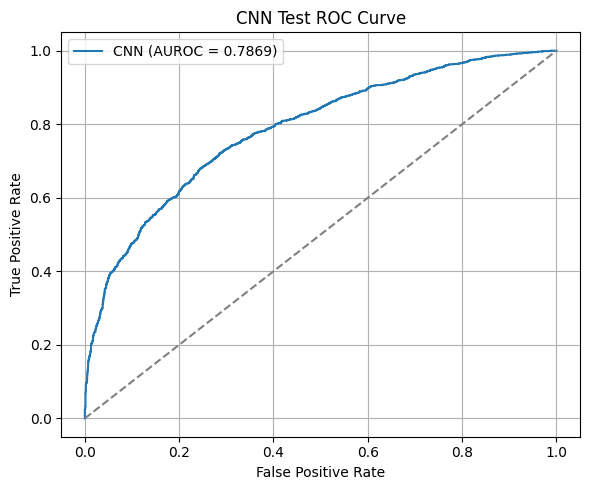

In [26]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve
)

print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["NC", "AD"],
    digits=4,
    zero_division=0
))

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(all_labels, all_predictions), 4)
)

test_auroc = roc_auc_score(all_labels, all_probabilities)
print("AUROC:", round(test_auroc, 4))

cm = confusion_matrix(
    all_labels, all_predictions, labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NC", "AD"]
).plot(cmap="Blues", values_format="d")

plt.title("CNN Test Confusion Matrix")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(all_labels, all_probabilities)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"CNN (AUROC = {test_auroc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN Test ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["NC", "AD"],
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame(report).T.loc[
    ["NC", "AD", "macro avg"],
    ["precision", "recall", "f1-score", "support"]
]

print("CNN Classification Metrics")
print(class_metrics.round(4).to_string())

summary = pd.DataFrame([{
    "Model": "CNN baseline",
    "Accuracy": test_acc,
    "Balanced Accuracy": balanced_accuracy_score(
        all_labels, all_predictions
    ),
    "Macro Precision": report["macro avg"]["precision"],
    "Macro Recall": report["macro avg"]["recall"],
    "Macro F1": report["macro avg"]["f1-score"],
    "AUROC": test_auroc
}])

print("\nCNN Summary")
print(summary.round(4).to_string(index=False))

CNN Classification Metrics
           precision  recall  f1-score  support
NC            0.7211  0.7947    0.7561   2440.0
AD            0.7139  0.6250    0.6665   2000.0
macro avg     0.7175  0.7098    0.7113   4440.0

CNN Summary
       Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  AUROC
CNN baseline    0.7182             0.7098           0.7175        0.7098    0.7113 0.7869
